# Figure S18 — Zr–Hf, Zr–Y, and Zr–Rb

This notebook plots the stored V2 melt-inclusion trace-element means. Replicated melt inclusions use their measured replicate 1σ SD. Single-analysis melt inclusions use an average secondary-standard relative 1σ for each element. The notebook does not recalculate trace-element concentrations or modify any source data.

## 1. Imports and shared Science Advances setup

This section reproduces the publication settings from `00_Setup/Plotting_Setup.ipynb`. There are no custom functions.

In [1]:
from pathlib import Path
import hashlib

import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib import font_manager
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
import numpy as np
import pandas as pd
from PIL import Image
from IPython.display import display

SINGLE_COLUMN_WIDTH_IN = 3.55
DOUBLE_COLUMN_WIDTH_IN = 7.25
BASE_TEXT_SIZE_PT = 8.0
PANEL_LABEL_SIZE_PT = 9.0
MINIMUM_TEXT_SIZE_PT = 6.0
MINIMUM_LINE_WIDTH_PT = 0.28
EXPORT_DPI = 300
PUBLICATION_FONT = 'Arial'

installed_font_names = {entry.name for entry in font_manager.fontManager.ttflist}
if PUBLICATION_FONT not in installed_font_names:
    raise RuntimeError('Arial is required. Install Arial and restart Python.')

mpl.rcParams.update({
    'font.family': 'sans-serif',
    'font.sans-serif': [PUBLICATION_FONT],
    'font.size': BASE_TEXT_SIZE_PT,
    'axes.labelsize': BASE_TEXT_SIZE_PT,
    'axes.titlesize': BASE_TEXT_SIZE_PT,
    'xtick.labelsize': BASE_TEXT_SIZE_PT,
    'ytick.labelsize': BASE_TEXT_SIZE_PT,
    'legend.fontsize': BASE_TEXT_SIZE_PT,
    'legend.title_fontsize': BASE_TEXT_SIZE_PT,
    'figure.facecolor': 'white',
    'axes.facecolor': 'white',
    'axes.grid': False,
    'axes.spines.top': True,
    'axes.spines.right': True,
    'axes.linewidth': 0.5,
    'lines.linewidth': 0.75,
    'xtick.direction': 'in',
    'ytick.direction': 'in',
    'xtick.major.width': 0.5,
    'ytick.major.width': 0.5,
    'xtick.minor.visible': False,
    'ytick.minor.visible': False,
    'savefig.dpi': EXPORT_DPI,
    'savefig.facecolor': 'white',
    'savefig.transparent': False,
    'pdf.fonttype': 42,
    'ps.fonttype': 42,
    'svg.fonttype': 'none',
})

print('Shared setup complete: Arial, 8-point text, 9-point bold panel labels, and 300 dpi export.')

Shared setup complete: Arial, 8-point text, 9-point bold panel labels, and 300 dpi export.


## 2. Figure S18 paths and plotting choices

Everything below is specific to Figure S18. The current S1 workbook contains the same trace-element values as the older combined workbook used by the exploratory version.

In [2]:
PROJECT_ROOT = None
for candidate in [Path.cwd(), *Path.cwd().parents]:
    if (candidate / 'SA_MI_Draft_FinalFigures_Work/DataSheets').is_dir():
        PROJECT_ROOT = candidate
        break
if PROJECT_ROOT is None:
    raise FileNotFoundError('Run this notebook from inside the Glacier Peak Efforts project.')

WORK_ROOT = PROJECT_ROOT / 'SA_MI_Draft_FinalFigures_Work'
CURRENT_DIRECTORY = WORK_ROOT / 'Nov6_AllFigures' / 'Figure_S18_Zr_Hf_Rb'
OUTPUT_DIRECTORY = CURRENT_DIRECTORY / 'Figure_S18_Zr_Hf_Rb_Final'
OUTPUT_DIRECTORY.mkdir(parents=True, exist_ok=True)

SOURCE_PATH = Path('/Users/annikadechert/Library/Mobile Documents/com~apple~CloudDocs/!!!Cal_Postdoc/Berkeley Postdoc/Glacier Peak Efforts/GP_Combined/SEIMS_SEM_Raman_LAICPMS/Combining_All_Dechert_Data/Combining_All_Dechert_Data_S1_20261110.xlsx')
STANDARDS_PATH = WORK_ROOT / 'DataSheets' / 'Updated_Oct20' / 'Dechert_S2_Standards.xlsx'
SOURCE_SHEET = 'MI_Hosts_Plag_Pxy'
SOURCE_HASH_BEFORE = hashlib.sha256(SOURCE_PATH.read_bytes()).hexdigest()
STANDARDS_HASH_BEFORE = hashlib.sha256(STANDARDS_PATH.read_bytes()).hexdigest()

SAMPLE_ORDER = ['74D', '74A', '75', '76A']
SAMPLE_COLORS = {'74D': '#F4A261', '74A': '#D55E00', '75': '#56B4E9', '76A': '#0072B2'}
SAMPLE_LABELS = {'74D': 'B Middle', '74A': 'B Base', '75': 'G Top', '76A': 'G Middle'}
PHASE_ORDER = ['plag', 'pxy']
PHASE_MARKERS = {'plag': 'o', 'pxy': 's'}
PHASE_LABELS = {'plag': 'Plagioclase-hosted MI', 'pxy': 'Pyroxene-hosted MI'}

MI_TRACE_COLUMNS = {
    'Zr': '90Zr_TE_MI_mean',
    'Hf': '178Hf_TE_MI_mean',
    'Y': '89Y_TE_MI_mean',
    'Rb': '85Rb_TE_MI_mean',
}
MI_TRACE_STD_COLUMNS = {
    'Zr': '90Zr_TE_MI_std_1sigma',
    'Hf': '178Hf_TE_MI_std_1sigma',
    'Y': '89Y_TE_MI_std_1sigma',
    'Rb': '85Rb_TE_MI_std_1sigma',
}
MI_TRACE_N_COLUMNS = {
    'Zr': '90Zr_TE_MI_n',
    'Hf': '178Hf_TE_MI_n',
    'Y': '89Y_TE_MI_n',
    'Rb': '85Rb_TE_MI_n',
}

# Read individual melt-inclusion standard analyses from the revised S2 layout.
# The date parser accepts Excel datetimes and numeric Excel serial dates.
def parse_excel_date(value):
    if pd.isna(value):
        return pd.NaT
    if isinstance(value, (int, float, np.integer, np.floating)):
        return pd.to_datetime(value, unit='D', origin='1899-12-30', errors='coerce')
    return pd.to_datetime(value, errors='coerce')


def read_melt_inclusion_standard_analyses(path, isotopes):
    raw = pd.read_excel(path, sheet_name='LA-ICP-MS', header=None)
    row_labels = raw.iloc[:, 0].astype('string').str.strip().str.upper()
    section_starts = raw.index[row_labels.eq('MELT INCLUSIONS')].tolist()
    if len(section_starts) != 1:
        raise ValueError(f'Expected one MELT INCLUSIONS section; found {len(section_starts)}.')
    section_start = section_starts[0]
    later_sections = raw.index[
        raw.index.to_series().gt(section_start)
        & row_labels.isin(['PLAGIOCLASE', 'ORTHOPYROXENE'])
    ].tolist()
    section_end = min(later_sections) if later_sections else len(raw)
    header_rows = [
        row_index for row_index in range(section_start + 1, section_end)
        if str(raw.iat[row_index, 0]).strip().casefold() == 'sample'
        and str(raw.iat[row_index, 1]).strip().casefold() == 'date'
        and str(raw.iat[row_index, 2]).strip().casefold() == 'type'
    ]
    if not header_rows:
        raise ValueError('No Sample/date/type header was found in the MELT INCLUSIONS section.')

    blocks = []
    for header_position, header_row in enumerate(header_rows):
        block_end = header_rows[header_position + 1] if header_position + 1 < len(header_rows) else section_end
        headers = [str(value).strip() if pd.notna(value) else '' for value in raw.iloc[header_row]]
        requested = ['Sample', 'date', 'type', *isotopes]
        column_positions = {name: headers.index(name) for name in requested if name in headers}
        missing_base_columns = [name for name in ['Sample', 'date', 'type'] if name not in column_positions]
        if missing_base_columns:
            raise KeyError(f'Missing standard-analysis columns: {missing_base_columns}')
        block = raw.iloc[header_row + 1:block_end, list(column_positions.values())].copy()
        block.columns = list(column_positions)
        blocks.append(block)

    analyses = pd.concat(blocks, ignore_index=True)
    analyses['date'] = analyses['date'].map(parse_excel_date)
    analyses['session'] = analyses['date'].dt.strftime('%Y%m%d')
    analyses['type'] = analyses['type'].astype('string').str.strip().str.casefold()
    analyses['standard'] = (
        analyses['Sample'].astype('string')
        .str.replace(r'\s*-\s*\d+\s*$', '', regex=True)
        .str.strip().str.upper()
    )
    return analyses


SESSION_STANDARD = {
    '20260615': 'T1-G',
    '20260618': 'ATHO',
    '20260622': 'ATHO',
}
STANDARD_ISOTOPES = {'Rb': '85Rb', 'Y': '89Y', 'Zr': '90Zr', 'Hf': '178Hf'}
standard_analyses = read_melt_inclusion_standard_analyses(
    STANDARDS_PATH, list(STANDARD_ISOTOPES.values())
)
standard_reproducibility_rows = []
for element, isotope in STANDARD_ISOTOPES.items():
    for session, standard in SESSION_STANDARD.items():
        values = pd.to_numeric(
            standard_analyses.loc[
                standard_analyses['session'].eq(session)
                & standard_analyses['type'].eq('secondary')
                & standard_analyses['standard'].eq(standard),
                isotope,
            ],
            errors='coerce',
        ).dropna()
        if len(values) < 2:
            raise ValueError(f'{session} {standard} {isotope}: fewer than two secondary analyses.')
        measured_mean = values.mean()
        sample_sd = values.std(ddof=1)
        if not np.isfinite(measured_mean) or measured_mean == 0:
            raise ValueError(f'{session} {standard} {isotope}: invalid measured mean.')
        standard_reproducibility_rows.append({
            'element': element,
            'isotope': isotope,
            'session': session,
            'standard': standard,
            'secondary_analysis_count': len(values),
            'measured_mean_ppm': measured_mean,
            'sample_sd_ppm': sample_sd,
            'relative_1sigma': sample_sd / abs(measured_mean),
        })
standard_reproducibility_audit = pd.DataFrame(standard_reproducibility_rows)
AVERAGE_STANDARD_RELATIVE_1SIGMA = (
    standard_reproducibility_audit.groupby('element', sort=False)['relative_1sigma'].mean().to_dict()
)
expected_relative_1sigma = {'Rb': 0.017740, 'Y': 0.039537, 'Zr': 0.055483, 'Hf': 0.043266}
for element, expected in expected_relative_1sigma.items():
    if not np.isclose(AVERAGE_STANDARD_RELATIVE_1SIGMA[element], expected, atol=5e-7):
        raise ValueError(f'{element}: unexpected average secondary-standard relative 1SD.')
PANEL_SPECS = [('A', 'Zr', 'Hf'), ('B', 'Zr', 'Y'), ('C', 'Zr', 'Rb')]

print(f'Source: {SOURCE_PATH.name} / {SOURCE_SHEET}')
print(f'Standards: {STANDARDS_PATH.name} / LA-ICP-MS')
print('Average secondary-standard relative 1SD (%):', {
    element: 100 * value for element, value in AVERAGE_STANDARD_RELATIVE_1SIGMA.items()
})
print(f'Output directory: {OUTPUT_DIRECTORY}')

Source: Combining_All_Dechert_Data_S1_20261110.xlsx / MI_Hosts_Plag_Pxy
Standards: Dechert_S2_Standards.xlsx / LA-ICP-MS
Average secondary-standard relative 1SD (%): {'Rb': 1.7740346509811795, 'Y': 3.953719718014783, 'Zr': 5.548325731770324, 'Hf': 4.3266391534360045}
Output directory: /Users/annikadechert/Library/Mobile Documents/com~apple~CloudDocs/!!!Cal_Postdoc/Berkeley Postdoc/Glacier Peak Efforts/SA_MI_Draft_FinalFigures_Work/Nov6_AllFigures/Figure_S18_Zr_Hf_Rb/Figure_S18_Zr_Hf_Rb_Final


## 3. Read the stored melt-inclusion values

Replicate analyses use the 1σ standard deviation stored in S1. Single analyses have no replicate standard deviation in S1 and are plotted without uncertainty bars.

In [3]:
source_columns = [
    'base_name', 'mineral_phase',
    *MI_TRACE_COLUMNS.values(),
    *MI_TRACE_STD_COLUMNS.values(),
    *MI_TRACE_N_COLUMNS.values(),
]
combined = pd.read_excel(SOURCE_PATH, sheet_name=SOURCE_SHEET, usecols=source_columns)

mi_work = combined.copy()
mi_work['sample_key'] = mi_work['base_name'].astype('string').str.extract(
    r'^(74D|74A|75|76A)', expand=False
)
mi_work['phase_key'] = (
    mi_work['mineral_phase'].astype('string').str.strip().str.casefold().replace({'opx': 'pxy'})
)
base_name_lower = mi_work['base_name'].astype('string').str.strip().str.casefold()
phase_lower = mi_work['mineral_phase'].astype('string').str.strip().str.casefold()
is_matrix_glass = (
    base_name_lower.str.contains(r'(?:^|[_\s-])mtx(?:$|[_\s-])', regex=True, na=False)
    | base_name_lower.str.contains('matrix glass', regex=False, na=False)
    | phase_lower.isin(['mtx', 'matrix', 'matrix glass', 'groundmass glass'])
)
mi_filter = (
    ~is_matrix_glass
    & mi_work['sample_key'].isin(SAMPLE_ORDER)
    & mi_work['phase_key'].isin(PHASE_ORDER)
)

mi = mi_work.loc[mi_filter, ['base_name', 'sample_key', 'phase_key']].copy()
for element, source_column in MI_TRACE_COLUMNS.items():
    mi[element] = pd.to_numeric(mi_work.loc[mi_filter, source_column], errors='coerce')
    mi[f'{element}_std_1sigma'] = pd.to_numeric(
        mi_work.loc[mi_filter, MI_TRACE_STD_COLUMNS[element]], errors='coerce'
    )
    mi[f'{element}_n'] = pd.to_numeric(
        mi_work.loc[mi_filter, MI_TRACE_N_COLUMNS[element]], errors='coerce'
    )
    replicate_mask = mi[f'{element}_n'].ge(2) & mi[f'{element}_std_1sigma'].notna()
    mi[f'{element}_plot_error_1sigma'] = mi[f'{element}_std_1sigma'].where(
        replicate_mask,
        mi[element].abs() * AVERAGE_STANDARD_RELATIVE_1SIGMA[element],
    )
    mi[f'{element}_error_source'] = np.where(
        replicate_mask,
        'replicate 1σ SD',
        'average secondary-standard relative 1σ',
    )

panel_audit_rows = []
for panel_label, x_element, y_element in PANEL_SPECS:
    finite = mi.dropna(subset=[x_element, y_element]).copy()
    replicate_mask = (
        finite[[f'{x_element}_std_1sigma', f'{y_element}_std_1sigma']].notna().all(axis=1)
        & finite[f'{x_element}_n'].ge(2)
        & finite[f'{y_element}_n'].ge(2)
    )
    panel_audit_rows.append({
        'panel': panel_label,
        'x_axis': x_element,
        'y_axis': y_element,
        'retained_MI_rows': len(finite),
        'replicate_SD_bars': int(replicate_mask.sum()),
        'average_standard_bars': int((~replicate_mask).sum()),
    })
panel_audit = pd.DataFrame(panel_audit_rows)

display(panel_audit)
display(mi.dropna(subset=['Zr', 'Hf', 'Y', 'Rb']).groupby(['sample_key', 'phase_key']).size().rename('n').reset_index())

,panel,x_axis,y_axis,retained_MI_rows,replicate_SD_bars,average_standard_bars
0,A,Zr,Hf,90,24,66
1,B,Zr,Y,90,24,66
2,C,Zr,Rb,90,24,66


,sample_key,phase_key,n
0,74A,plag,12
1,74A,pxy,16
2,74D,plag,7
3,74D,pxy,6
4,75,plag,9
5,75,pxy,12
6,76A,plag,12
7,76A,pxy,16


## 4. Plot and export Figure S18

Saved: /Users/annikadechert/Library/Mobile Documents/com~apple~CloudDocs/!!!Cal_Postdoc/Berkeley Postdoc/Glacier Peak Efforts/SA_MI_Draft_FinalFigures_Work/Nov6_AllFigures/Figure_S18_Zr_Hf_Rb/Figure_S18_Zr_Hf_Rb_Final/Figure_S18_Zr_Hf_Rb_average_standard_errors.pdf
Saved: /Users/annikadechert/Library/Mobile Documents/com~apple~CloudDocs/!!!Cal_Postdoc/Berkeley Postdoc/Glacier Peak Efforts/SA_MI_Draft_FinalFigures_Work/Nov6_AllFigures/Figure_S18_Zr_Hf_Rb/Figure_S18_Zr_Hf_Rb_Final/Figure_S18_Zr_Hf_Rb_average_standard_errors.png
Saved: /Users/annikadechert/Library/Mobile Documents/com~apple~CloudDocs/!!!Cal_Postdoc/Berkeley Postdoc/Glacier Peak Efforts/SA_MI_Draft_FinalFigures_Work/Nov6_AllFigures/Figure_S18_Zr_Hf_Rb/Figure_S18_Zr_Hf_Rb_Final/Figure_S18_Zr_Hf_Rb_average_standard_errors.svg


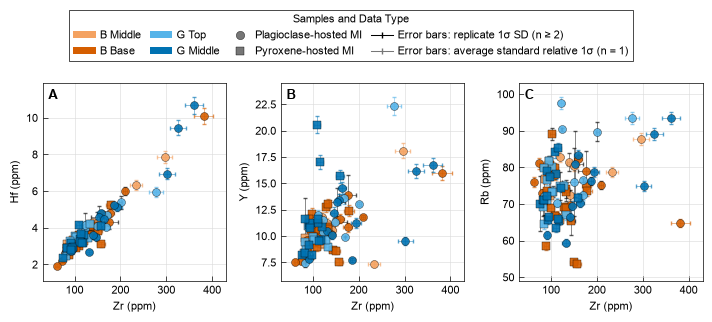

In [4]:
figure, axes = plt.subplots(
    1, 3,
    figsize=(DOUBLE_COLUMN_WIDTH_IN, 3.35),
)

for axis, (panel_label, x_element, y_element) in zip(axes, PANEL_SPECS):
    plotted = mi.dropna(subset=[x_element, y_element]).copy()

    for sample_key in SAMPLE_ORDER:
        for phase_key in PHASE_ORDER:
            group = plotted.loc[
                plotted['sample_key'].eq(sample_key)
                & plotted['phase_key'].eq(phase_key)
            ]
            replicate_spots = group.loc[
                group[[f'{x_element}_std_1sigma', f'{y_element}_std_1sigma']].notna().all(axis=1)
                & group[f'{x_element}_n'].ge(2)
                & group[f'{y_element}_n'].ge(2)
            ]
            single_spots = group.loc[~group.index.isin(replicate_spots.index)]

            axis.errorbar(
                replicate_spots[x_element], replicate_spots[y_element],
                xerr=replicate_spots[f'{x_element}_plot_error_1sigma'],
                yerr=replicate_spots[f'{y_element}_plot_error_1sigma'],
                fmt='none', ecolor='black', elinewidth=0.5, capsize=1.5,
                alpha=0.65, zorder=2,
            )
            axis.errorbar(
                single_spots[x_element], single_spots[y_element],
                xerr=single_spots[f'{x_element}_plot_error_1sigma'],
                yerr=single_spots[f'{y_element}_plot_error_1sigma'],
                fmt='none', ecolor=SAMPLE_COLORS[sample_key], elinewidth=0.5, capsize=1.5,
                alpha=0.65, zorder=2,
            )
            axis.scatter(
                group[x_element], group[y_element],
                marker=PHASE_MARKERS[phase_key],
                s=(6.0 - MINIMUM_LINE_WIDTH_PT) ** 2,
                facecolor=SAMPLE_COLORS[sample_key],
                edgecolor='black',
                linewidth=MINIMUM_LINE_WIDTH_PT,
                alpha=0.90,
                zorder=3,
            )

    x_values = np.concatenate([
        plotted[x_element].to_numpy(),
        (plotted[x_element] - plotted[f'{x_element}_plot_error_1sigma'].fillna(0)).to_numpy(),
        (plotted[x_element] + plotted[f'{x_element}_plot_error_1sigma'].fillna(0)).to_numpy(),
    ])
    y_values = np.concatenate([
        plotted[y_element].to_numpy(),
        (plotted[y_element] - plotted[f'{y_element}_plot_error_1sigma'].fillna(0)).to_numpy(),
        (plotted[y_element] + plotted[f'{y_element}_plot_error_1sigma'].fillna(0)).to_numpy(),
    ])
    finite_x = x_values[np.isfinite(x_values)]
    finite_y = y_values[np.isfinite(y_values)]
    x_padding = 0.08 * (finite_x.max() - finite_x.min())
    y_padding = 0.08 * (finite_y.max() - finite_y.min())
    axis.set_xlim(max(0, finite_x.min() - x_padding), finite_x.max() + x_padding)
    axis.set_ylim(max(0, finite_y.min() - y_padding), finite_y.max() + y_padding)

    axis.set_xlabel('Zr (ppm)')
    axis.set_ylabel(f'{y_element} (ppm)')
    axis.grid(True, color='#D9D9D9', linewidth=0.4)
    axis.set_axisbelow(True)
    axis.text(
        0.03, 0.97, panel_label,
        transform=axis.transAxes,
        ha='left', va='top',
        fontsize=PANEL_LABEL_SIZE_PT,
        fontweight='bold',
        bbox={'facecolor': 'white', 'edgecolor': 'none', 'alpha': 0.80, 'pad': 0.3},
        zorder=10,
    )
    for spine in axis.spines.values():
        spine.set_visible(True)
        spine.set_linewidth(0.5)

sample_handles = [
    Patch(facecolor=SAMPLE_COLORS[key], edgecolor='none', label=SAMPLE_LABELS[key])
    for key in SAMPLE_ORDER
]
phase_handles = [
    Line2D(
        [], [], linestyle='none', marker=PHASE_MARKERS[key],
        markerfacecolor='#777777', markeredgecolor='black',
        markeredgewidth=MINIMUM_LINE_WIDTH_PT, markersize=6.0,
        label=PHASE_LABELS[key],
    )
    for key in PHASE_ORDER
]
uncertainty_handles = [
    Line2D([], [], color='black', linewidth=0.75, marker='|', markersize=5,
           label='Error bars: replicate 1σ SD (n ≥ 2)'),
    Line2D([], [], color='#777777', linewidth=0.75, marker='|', markersize=5,
           label='Error bars: average standard relative 1σ (n = 1)'),
]
legend = figure.legend(
    handles=sample_handles + phase_handles + uncertainty_handles,
    title='Samples and Data Type',
    loc='upper center',
    bbox_to_anchor=(0.5, 0.985),
    ncol=4,
    frameon=True,
    fancybox=False,
    facecolor='white',
    edgecolor='black',
    framealpha=1.0,
    borderpad=0.4,
    handletextpad=0.4,
    columnspacing=0.8,
)
legend.get_frame().set_linewidth(0.5)

figure.subplots_adjust(left=0.075, right=0.985, bottom=0.16, top=0.75, wspace=0.30)

PDF_PATH = OUTPUT_DIRECTORY / 'Figure_S18_Zr_Hf_Rb_average_standard_errors.pdf'
PNG_PATH = OUTPUT_DIRECTORY / 'Figure_S18_Zr_Hf_Rb_average_standard_errors.png'
SVG_PATH = OUTPUT_DIRECTORY / 'Figure_S18_Zr_Hf_Rb_average_standard_errors.svg'
figure.savefig(PDF_PATH, format='pdf', dpi=EXPORT_DPI, facecolor='white', transparent=False)
figure.savefig(PNG_PATH, format='png', dpi=EXPORT_DPI, facecolor='white', transparent=False)
figure.savefig(SVG_PATH, format='svg', dpi=EXPORT_DPI, facecolor='white', transparent=False)

print(f'Saved: {PDF_PATH}')
print(f'Saved: {PNG_PATH}')
print(f'Saved: {SVG_PATH}')
plt.show()

## 5. Short output check

In [5]:
panel_audit.to_csv(OUTPUT_DIRECTORY / 'Figure_S18_Zr_Hf_Rb_panel_audit.csv', index=False)
standard_reproducibility_audit.to_csv(
    OUTPUT_DIRECTORY / 'Figure_S18_Zr_Hf_Rb_standard_reproducibility_audit.csv', index=False
)
if panel_audit['retained_MI_rows'].tolist() != [90, 90, 90]:
    raise ValueError('The established 90-MI plotting population has changed.')
if panel_audit['replicate_SD_bars'].tolist() != [24, 24, 24]:
    raise ValueError('The established replicate-SD population has changed.')
if panel_audit['average_standard_bars'].tolist() != [66, 66, 66]:
    raise ValueError('The established single-spot uncertainty population has changed.')
if hashlib.sha256(SOURCE_PATH.read_bytes()).hexdigest() != SOURCE_HASH_BEFORE:
    raise RuntimeError('The source workbook changed during execution.')
if hashlib.sha256(STANDARDS_PATH.read_bytes()).hexdigest() != STANDARDS_HASH_BEFORE:
    raise RuntimeError('The standards workbook changed during execution.')

with Image.open(PNG_PATH) as image:
    png_dimensions = image.size
if png_dimensions != (2175, 1005):
    raise ValueError(f'Unexpected PNG dimensions: {png_dimensions}')
if b'/Type3' in PDF_PATH.read_bytes():
    raise ValueError('The PDF contains Type 3 fonts.')
if '<text' not in SVG_PATH.read_text(encoding='utf-8'):
    raise ValueError('The SVG does not retain live text.')

print('Check passed: 90 melt inclusions per panel; source data unchanged.')
print(f'Final size: {DOUBLE_COLUMN_WIDTH_IN:.2f} x 3.35 in; PNG: {png_dimensions[0]} x {png_dimensions[1]} px.')

Check passed: 90 melt inclusions per panel; source data unchanged.
Final size: 7.25 x 3.35 in; PNG: 2175 x 1005 px.


## 6. Replot the replicate-SD-only version

Regenerate the regular Figure S18 exports from the current S1 data, retaining replicate-SD-only error bars.

Saved: /Users/annikadechert/Library/Mobile Documents/com~apple~CloudDocs/!!!Cal_Postdoc/Berkeley Postdoc/Glacier Peak Efforts/SA_MI_Draft_FinalFigures_Work/Nov6_AllFigures/Figure_S18_Zr_Hf_Rb/Figure_S18_Zr_Hf_Rb_Final/Figure_S18_Zr_Hf_Rb.pdf
Saved: /Users/annikadechert/Library/Mobile Documents/com~apple~CloudDocs/!!!Cal_Postdoc/Berkeley Postdoc/Glacier Peak Efforts/SA_MI_Draft_FinalFigures_Work/Nov6_AllFigures/Figure_S18_Zr_Hf_Rb/Figure_S18_Zr_Hf_Rb_Final/Figure_S18_Zr_Hf_Rb.png
Saved: /Users/annikadechert/Library/Mobile Documents/com~apple~CloudDocs/!!!Cal_Postdoc/Berkeley Postdoc/Glacier Peak Efforts/SA_MI_Draft_FinalFigures_Work/Nov6_AllFigures/Figure_S18_Zr_Hf_Rb/Figure_S18_Zr_Hf_Rb_Final/Figure_S18_Zr_Hf_Rb.svg


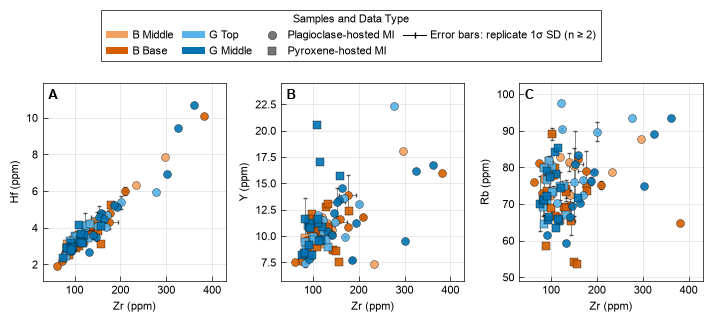

In [6]:
figure, axes = plt.subplots(
    1, 3,
    figsize=(DOUBLE_COLUMN_WIDTH_IN, 3.35),
)

for axis, (panel_label, x_element, y_element) in zip(axes, PANEL_SPECS):
    plotted = mi.dropna(subset=[x_element, y_element]).copy()

    for sample_key in SAMPLE_ORDER:
        for phase_key in PHASE_ORDER:
            group = plotted.loc[
                plotted['sample_key'].eq(sample_key)
                & plotted['phase_key'].eq(phase_key)
            ]
            replicate_spots = group.loc[
                group[[f'{x_element}_std_1sigma', f'{y_element}_std_1sigma']].notna().all(axis=1)
                & group[f'{x_element}_n'].ge(2)
                & group[f'{y_element}_n'].ge(2)
            ]
            single_spots = group.loc[~group.index.isin(replicate_spots.index)]

            axis.errorbar(
                replicate_spots[x_element], replicate_spots[y_element],
                xerr=replicate_spots[f'{x_element}_plot_error_1sigma'],
                yerr=replicate_spots[f'{y_element}_plot_error_1sigma'],
                fmt='none', ecolor='black', elinewidth=0.5, capsize=1.5,
                alpha=0.65, zorder=2,
            )
            axis.scatter(
                group[x_element], group[y_element],
                marker=PHASE_MARKERS[phase_key],
                s=(6.0 - MINIMUM_LINE_WIDTH_PT) ** 2,
                facecolor=SAMPLE_COLORS[sample_key],
                edgecolor='black',
                linewidth=MINIMUM_LINE_WIDTH_PT,
                alpha=0.90,
                zorder=3,
            )

    x_values = np.concatenate([
        plotted[x_element].to_numpy(),
        (plotted[x_element] - plotted[f'{x_element}_plot_error_1sigma'].fillna(0)).to_numpy(),
        (plotted[x_element] + plotted[f'{x_element}_plot_error_1sigma'].fillna(0)).to_numpy(),
    ])
    y_values = np.concatenate([
        plotted[y_element].to_numpy(),
        (plotted[y_element] - plotted[f'{y_element}_plot_error_1sigma'].fillna(0)).to_numpy(),
        (plotted[y_element] + plotted[f'{y_element}_plot_error_1sigma'].fillna(0)).to_numpy(),
    ])
    finite_x = x_values[np.isfinite(x_values)]
    finite_y = y_values[np.isfinite(y_values)]
    x_padding = 0.08 * (finite_x.max() - finite_x.min())
    y_padding = 0.08 * (finite_y.max() - finite_y.min())
    axis.set_xlim(max(0, finite_x.min() - x_padding), finite_x.max() + x_padding)
    axis.set_ylim(max(0, finite_y.min() - y_padding), finite_y.max() + y_padding)

    axis.set_xlabel('Zr (ppm)')
    axis.set_ylabel(f'{y_element} (ppm)')
    axis.grid(True, color='#D9D9D9', linewidth=0.4)
    axis.set_axisbelow(True)
    axis.text(
        0.03, 0.97, panel_label,
        transform=axis.transAxes,
        ha='left', va='top',
        fontsize=PANEL_LABEL_SIZE_PT,
        fontweight='bold',
        bbox={'facecolor': 'white', 'edgecolor': 'none', 'alpha': 0.80, 'pad': 0.3},
        zorder=10,
    )
    for spine in axis.spines.values():
        spine.set_visible(True)
        spine.set_linewidth(0.5)

sample_handles = [
    Patch(facecolor=SAMPLE_COLORS[key], edgecolor='none', label=SAMPLE_LABELS[key])
    for key in SAMPLE_ORDER
]
phase_handles = [
    Line2D(
        [], [], linestyle='none', marker=PHASE_MARKERS[key],
        markerfacecolor='#777777', markeredgecolor='black',
        markeredgewidth=MINIMUM_LINE_WIDTH_PT, markersize=6.0,
        label=PHASE_LABELS[key],
    )
    for key in PHASE_ORDER
]
uncertainty_handles = [
    Line2D([], [], color='black', linewidth=0.75, marker='|', markersize=5,
           label='Error bars: replicate 1σ SD (n ≥ 2)'),
]
legend = figure.legend(
    handles=sample_handles + phase_handles + uncertainty_handles,
    title='Samples and Data Type',
    loc='upper center',
    bbox_to_anchor=(0.5, 0.985),
    ncol=4,
    frameon=True,
    fancybox=False,
    facecolor='white',
    edgecolor='black',
    framealpha=1.0,
    borderpad=0.4,
    handletextpad=0.4,
    columnspacing=0.8,
)
legend.get_frame().set_linewidth(0.5)

figure.subplots_adjust(left=0.075, right=0.985, bottom=0.16, top=0.75, wspace=0.30)

PDF_PATH = OUTPUT_DIRECTORY / 'Figure_S18_Zr_Hf_Rb.pdf'
PNG_PATH = OUTPUT_DIRECTORY / 'Figure_S18_Zr_Hf_Rb.png'
SVG_PATH = OUTPUT_DIRECTORY / 'Figure_S18_Zr_Hf_Rb.svg'
figure.savefig(PDF_PATH, format='pdf', dpi=EXPORT_DPI, facecolor='white', transparent=False)
figure.savefig(PNG_PATH, format='png', dpi=EXPORT_DPI, facecolor='white', transparent=False)
figure.savefig(SVG_PATH, format='svg', dpi=EXPORT_DPI, facecolor='white', transparent=False)

print(f'Saved: {PDF_PATH}')
print(f'Saved: {PNG_PATH}')
print(f'Saved: {SVG_PATH}')
plt.show()